# 14 · Evaluation on the holdout seasons

Every modelling decision was made on 2008/09-2013/14. This notebook opens
the **holdout seasons 2014/15-2020/21** (2,660 La Liga fixtures, 266 of them
Barcelona's) for the first time and asks:

1. How good are the models, and how do they compare with the **betting
   market**?
2. Are the probabilities **calibrated**?
3. Is performance **stable** season by season?
4. What does the confusion matrix hide, and why is accuracy the wrong
   headline?
5. How good is the **score model**?

Predictions are the walk-forward ones: each season is predicted by a model
trained only on earlier seasons.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca import config
from barca.data import store
from barca.models import backtest, data, metrics
from barca.models.baselines import EloModel, LogisticModel, NaiveModel, PoissonModel
from barca.models.gbm import LightGBMModel, RandomForestModel, XGBoostModel
from barca.visualization import style

warnings.filterwarnings("ignore")
style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(4)

HOLDOUT = tuple(range(2014, 2021))
DEV = tuple(range(2008, 2014))
league = data.league_dataset(store.features("fixtures"))
prod = pl.read_parquet(config.MODELS / "match_outcome" / "predictions_league.parquet")
barca_pred = pl.read_parquet(config.MODELS / "match_outcome" / "predictions_barca.parquet")
card = json.loads((config.MODELS / "match_outcome" / "model_card.json").read_text())
print(card["model"])

Equal-weight ensemble: Elo ordered logit + Poisson goals model + LightGBM


## 1. Holdout results: all models and the market

In [2]:
preds = {"ensemble (production)": prod.filter(pl.col("season_start").is_in(HOLDOUT))}
for name, make in [("naive", NaiveModel), ("elo", EloModel), ("poisson", lambda: PoissonModel(dixon_coles=False)),
                   ("logistic", lambda: LogisticModel(C=0.001)), ("random_forest", RandomForestModel),
                   ("xgboost", XGBoostModel), ("lightgbm", LightGBMModel)]:
    preds[name], _ = backtest.walk_forward(league, make, test_seasons=HOLDOUT)

hold = league.rows(np.isin(league.season, HOLDOUT))
rows = [{"model": k, **backtest.score(v)} for k, v in preds.items()]
for book, label in [("avg", "market: average odds"), ("b365", "market: Bet365")]:
    mp = data.market_probs(hold.meta, book, league.classes)
    rows.append({"model": label, **metrics.summary(hold.y, mp)})
table = pl.DataFrame(rows).sort("log_loss")
table

model,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""market: average odds""",2660,0.9529,0.5652,0.1897,0.5414,0.3978,0.0187
"""market: Bet365""",2660,0.9537,0.5658,0.1899,0.5402,0.3955,0.0143
"""ensemble (production)""",2660,0.9677,0.5753,0.1940,0.5293,0.3825,0.0172
"""poisson""",2660,0.9685,0.5757,0.1942,0.5297,0.3840,0.0181
"""elo""",2660,0.9701,0.5772,0.1948,0.5297,0.3841,0.0232
"""logistic""",2660,0.9716,0.5774,0.1947,0.5297,0.3911,0.0180
"""random_forest""",2660,0.9722,0.5774,0.1948,0.5293,0.3909,0.0172
"""xgboost""",2660,0.9730,0.5782,0.1952,0.5297,0.3915,0.0234
"""lightgbm""",2660,0.9743,0.5791,0.1953,0.5274,0.3900,0.0195


On matches none of its design choices ever saw, the production ensemble is
again the best model, which is the evidence that the selection protocol
did not over-fit the development window. Among single models the order
*does* shift. Poisson and Elo stay near the top, but LightGBM, level with Elo
in development, is the weakest trained model on the holdout. Single-model
rankings on a few thousand football matches are noisy, which is exactly why
production relies on an average rather than on whichever model looked best
once.

**The betting market is better.** The gap to the market's average odds is
about 0.01-0.015 in log loss. Bookmakers price in information no
results-based model has (team news, injuries, suspensions, motivation,
weather, money from informed bettors), so closing that gap from public
results data alone would be surprising. The market is the ceiling, and the
model sits closer to it than to the naive floor. Pinnacle's closing odds,
the sharpest public benchmark, only exist from 2012/13:

In [3]:
mp = data.market_probs(hold.meta, "psc", league.classes)
ok = ~np.isnan(mp).any(axis=1)
ens_h = preds["ensemble (production)"]
pl.DataFrame([
    {"model": "ensemble", **metrics.summary(hold.y[ok], backtest.probs(ens_h)[ok])},
    {"model": "market: Pinnacle closing", **metrics.summary(hold.y[ok], mp[ok])},
]).select("model", "n", "log_loss", "rps", "accuracy", "ece")

model,n,log_loss,rps,accuracy,ece
str,i64,f64,f64,f64,f64
"""ensemble""",2659,0.9677,0.1940,0.5291,0.0171
"""market: Pinnacle closing""",2659,0.9482,0.1883,0.5476,0.0138


### How much of the way from naive to market?

In [4]:
ll = dict(zip(table["model"], table["log_loss"], strict=True))
naive, market = ll["naive"], ll["market: average odds"]
share = pl.DataFrame([{"model": k, "gap_closed": (naive - v) / (naive - market)} for k, v in ll.items() if k != "naive"]).sort(
    "gap_closed", descending=True)
share

model,gap_closed
str,f64
"""market: average odds""",1.0000
"""market: Bet365""",0.9925
"""ensemble (production)""",0.8695
"""poisson""",0.8622
"""elo""",0.8485
"""logistic""",0.8346
"""random_forest""",0.8294
"""xgboost""",0.8223
"""lightgbm""",0.8116


The ensemble closes most of the distance between knowing nothing (always
predicting base rates) and the betting market, using nothing but past
results and ratings.

## 2. Barcelona's matches

In [5]:
bh = barca_pred.filter(pl.col("season_start").is_in(HOLDOUT))
yb = bh["barca_result"].replace_strict({"W": 0, "D": 1, "L": 2}, return_dtype=pl.Int64).to_numpy()
pb = bh.select("p_win", "p_draw", "p_loss").to_numpy()
mb = bh.select("mkt_win", "mkt_draw", "mkt_loss").to_numpy()
okb = ~np.isnan(mb).any(axis=1)
nb = np.tile(np.bincount(yb, minlength=3) / len(yb), (len(yb), 1))
pl.DataFrame([
    {"model": "ensemble", **metrics.summary(yb, pb)},
    {"model": "market: average odds", **metrics.summary(yb[okb], mb[okb])},
    {"model": "base rate (in hindsight)", **metrics.summary(yb, nb)},
]).select("model", "n", "log_loss", "brier", "rps", "accuracy", "ece")

model,n,log_loss,brier,rps,accuracy,ece
str,i64,f64,f64,f64,f64,f64
"""ensemble""",266,0.7578,0.4269,0.1445,0.7180,0.0370
"""market: average odds""",266,0.7488,0.4208,0.1422,0.7143,0.0505
"""base rate (in hindsight)""",266,0.7899,0.4472,0.1521,0.7143,0.0000


Barcelona's matches are easier to call than the average fixture (a 70%+
favourite most weeks), and the ordering holds: the market is best, the
ensemble close behind. The "base rate in hindsight" row uses the holdout
seasons' own W/D/L frequencies, which no real forecaster could know, and
the ensemble still beats it.

## 3. Calibration

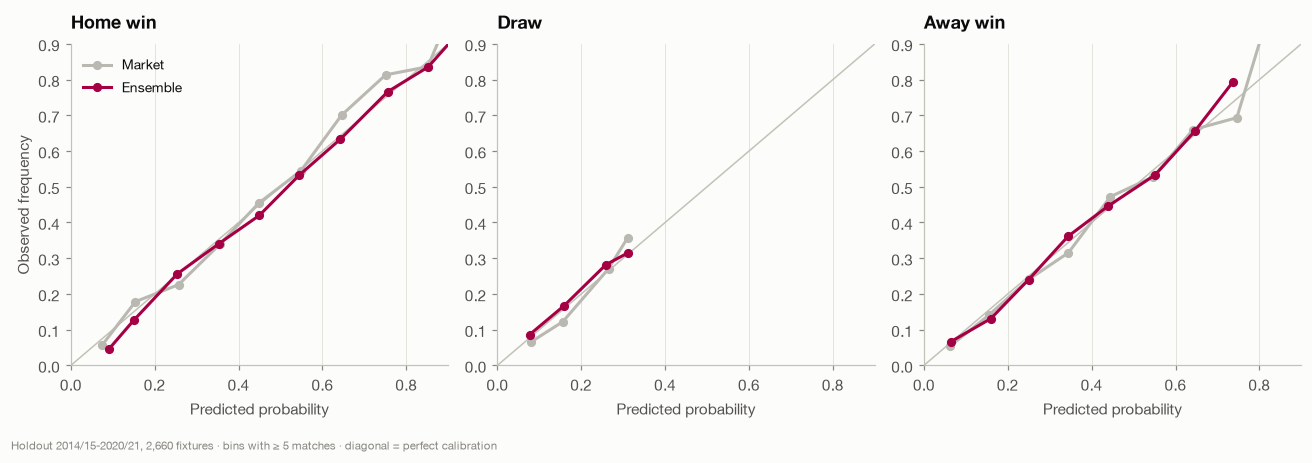

ECE, ensemble: 0.0172  market: 0.0187


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
yh, ph = hold.y, backtest.probs(ens_h)
mpa = data.market_probs(hold.meta, "avg", league.classes)
for k, (ax, name) in enumerate(zip(axes, ["Home win", "Draw", "Away win"], strict=True)):
    ax.plot([0, 1], [0, 1], color=style.AXIS, lw=1)
    for probs, col, lab in ((mpa, style.NEUTRAL, "Market"), (ph, style.BARCA, "Ensemble")):
        rel = metrics.reliability(yh, probs, k, bins=10)
        ax.plot([r["predicted"] for r in rel], [r["observed"] for r in rel], marker="o", color=col, lw=2, ms=5, label=lab)
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 0.9)
    ax.set_title(name)
    ax.set_xlabel("Predicted probability")
    ax.grid(axis="both")
axes[0].set_ylabel("Observed frequency")
axes[0].legend(loc="upper left")
style.caption(axes[0], "Holdout 2014/15-2020/21, 2,660 fixtures · bins with ≥ 5 matches · diagonal = perfect calibration")
fig.tight_layout()
style.savefig(fig, "14_calibration")
plt.show()
print("ECE, ensemble:", round(metrics.ece(yh, ph), 4), " market:", round(metrics.ece(yh, mpa), 4))

The ensemble's probabilities are well calibrated for home and away wins
across the whole range, which is what matters when the app says "54%". Its
expected calibration error (0.017) is as low as the market's (0.019). Draw
probabilities never exceed about 35% for any model, including the market:
draws are hard to separate, and nobody predicts a 45% draw.

## 4. Stability by season

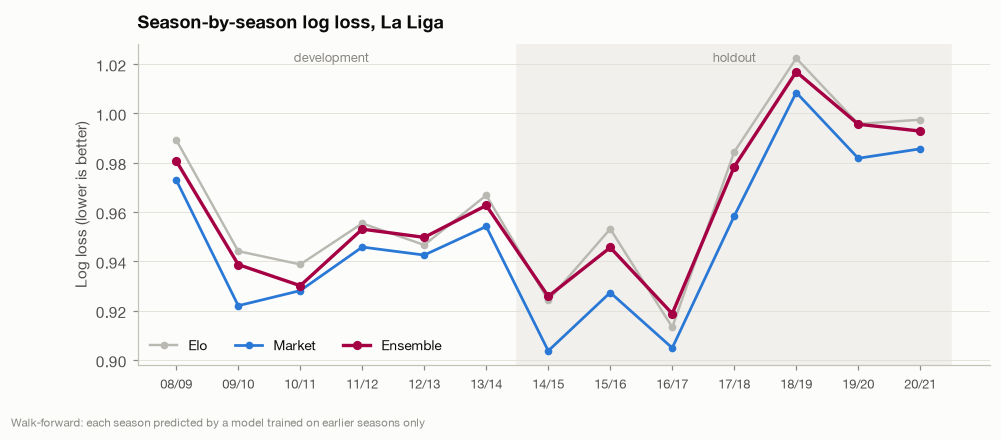

season_start,log_loss,elo,market
i64,f64,f64,f64
2008,0.9807,0.9892,0.9730
2009,0.9387,0.9441,0.9220
2010,0.9301,0.9388,0.9281
2011,0.9531,0.9554,0.9458
2012,0.9497,0.9466,0.9425
2013,0.9627,0.9668,0.9541
2014,0.9258,0.9242,0.9037
2015,0.9456,0.9532,0.9273
2016,0.9188,0.9133,0.9049


In [7]:
seasons = backtest.by_season(prod).select("season_start", "log_loss")
elo_all, _ = backtest.walk_forward(league, EloModel)
elo_s = backtest.by_season(elo_all).select("season_start", pl.col("log_loss").alias("elo"))
mkt_rows = []
for s in data.TEST_SEASONS:
    r = league.rows(league.season == s)
    m = data.market_probs(r.meta, "avg", league.classes)
    mkt_rows.append({"season_start": s, "market": metrics.log_loss(r.y, m)})
stab = seasons.join(elo_s, on="season_start").join(pl.DataFrame(mkt_rows), on="season_start")

fig, ax = plt.subplots(figsize=(10, 3.8))
x = stab["season_start"].to_numpy()
ax.axvspan(2013.5, 2020.5, color="#f1f0ec", zorder=0)
ax.text(2017, stab["log_loss"].max() + 0.004, "holdout", ha="center", fontsize=8.5, color=style.MUTED)
ax.text(2010.5, stab["log_loss"].max() + 0.004, "development", ha="center", fontsize=8.5, color=style.MUTED)
ax.plot(x, stab["elo"], color=style.NEUTRAL, lw=1.6, marker="o", ms=4, label="Elo")
ax.plot(x, stab["market"], color=style.OPPONENT, lw=1.8, marker="o", ms=4, label="Market")
ax.plot(x, stab["log_loss"], color=style.BARCA, lw=2.2, marker="o", ms=5, label="Ensemble")
ax.set_xticks(x, [f"{s % 100:02d}/{(s + 1) % 100:02d}" for s in x], fontsize=8.5)
ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Season-by-season log loss, La Liga")
ax.legend(ncols=3, loc="lower left")
style.caption(ax, "Walk-forward: each season predicted by a model trained on earlier seasons only")
style.savefig(fig, "14_season_stability")
plt.show()
stab

Season difficulty moves all three lines together: some seasons are simply
more predictable (a dominant top two, a clear relegation battle) than
others. The ensemble beats Elo in 10 of 13 seasons and tracks the market at
a fairly constant distance (0.007-0.022). There is no season where it
collapses.

## 5. Confusion matrix, and why accuracy is the wrong headline

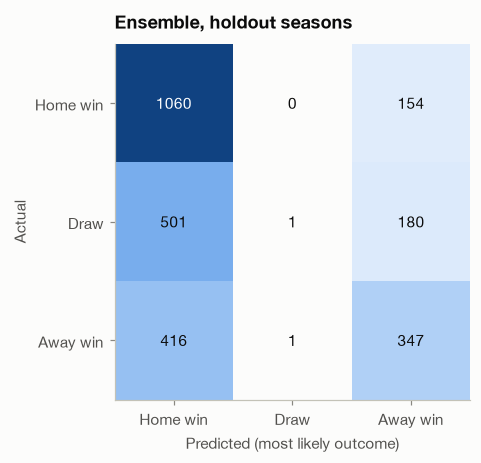

accuracy: 0.529 · draws predicted as most likely: 2 of 2660


In [8]:
cm = metrics.confusion(yh, ph)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap=style.HEAT_BLUE)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else style.INK)
ax.set_xticks(range(3), ["Home win", "Draw", "Away win"])
ax.set_yticks(range(3), ["Home win", "Draw", "Away win"])
ax.set_xlabel("Predicted (most likely outcome)")
ax.set_ylabel("Actual")
ax.grid(False)
ax.set_title("Ensemble, holdout seasons")
style.savefig(fig, "14_confusion")
plt.show()
print(f"accuracy: {metrics.accuracy(yh, ph):.3f} · draws predicted as most likely: {int(cm[:, 1].sum())} of {len(yh)}")

The model almost never names a draw as the single most likely outcome,
although about a quarter of matches end drawn. That is not a flaw.
A draw is rarely *the most likely* of three outcomes, even when it is
quite likely. A model that picked draws more often would be less accurate
**and** worse calibrated. It is also why accuracy (about 53%) is reported
but never optimised: it throws away everything a probability says except
which number is biggest.

## 6. Does disagreeing with the market pay?

Where the model and the market disagree most, who is right? For each
holdout match, the log-loss difference between ensemble and market, by the
size of their disagreement on the home-win probability:

In [9]:
dis = pl.DataFrame({
    "gap": ph[:, 0] - mpa[:, 0],
    "ll_model": -np.log(np.clip(ph[np.arange(len(yh)), yh], 1e-12, 1)),
    "ll_market": -np.log(np.clip(mpa[np.arange(len(yh)), yh], 1e-12, 1)),
}).with_columns(pl.col("gap").abs().qcut(5, labels=["Q1 (agree)", "Q2", "Q3", "Q4", "Q5 (disagree)"]).alias("disagreement"))
dis.group_by("disagreement").agg(
    pl.len().alias("n"), pl.col("gap").abs().mean().alias("mean_abs_gap"),
    pl.col("ll_model").mean().alias("model_ll"), pl.col("ll_market").mean().alias("market_ll"),
).with_columns((pl.col("model_ll") - pl.col("market_ll")).alias("model_minus_market")).sort("disagreement")

disagreement,n,mean_abs_gap,model_ll,market_ll,model_minus_market
cat,u32,f64,f64,f64,f64
"""Q1 (agree)""",532,0.0071,0.9042,0.9016,0.0026
"""Q2""",532,0.0223,0.9367,0.9359,0.0008
"""Q3""",532,0.0381,1.0109,0.9962,0.0147
"""Q4""",532,0.0591,0.9617,0.9494,0.0123
"""Q5 (disagree)""",532,0.1061,1.0250,0.9814,0.0436


When the two agree, their log losses are identical. As they disagree more,
the market is increasingly right: the model's disagreements are mostly
errors, not hidden value. That is the signature of the missing information
(team news above all) and a good reason **not** to treat the model's edge
over the odds as a betting signal.

## 7. The score model

The Poisson member gives expected goals for each side and a full scoreline
distribution. How good is it on the holdout seasons?

In [10]:
xg_h = prod.filter(pl.col("season_start").is_in(HOLDOUT))
hg, ag = xg_h["home_goals"].to_numpy(), xg_h["away_goals"].to_numpy()
top = [json.loads(s) for s in xg_h["scores"]]
p_actual = []
hit1 = hit3 = 0
for t, h, a in zip(top, hg, ag, strict=True):
    probs = {(d["home"], d["away"]): d["p"] for d in t}
    p_actual.append(probs.get((h, a), 0.0))
    ranked = [(d["home"], d["away"]) for d in t]
    hit1 += ranked[0] == (h, a)
    hit3 += (h, a) in ranked[:3]
n = len(hg)
tot_pred = xg_h["xg_home"].to_numpy() + xg_h["xg_away"].to_numpy()
print(f"mean predicted goals per match {tot_pred.mean():.2f} vs actual {(hg + ag).mean():.2f}")
print(f"mean predicted home goals {xg_h['xg_home'].mean():.2f} vs actual {hg.mean():.2f}; away {xg_h['xg_away'].mean():.2f} vs {ag.mean():.2f}")
print(f"most likely scoreline correct: {hit1 / n:.1%} · actual score in the top 3: {hit3 / n:.1%}")
print(f"average probability given to the actual score (when in the stored top 8): {np.mean(p_actual):.3f}")

mean predicted goals per match 2.64 vs actual 2.66
mean predicted home goals 1.53 vs actual 1.52; away 1.10 vs 1.14
most likely scoreline correct: 13.4% · actual score in the top 3: 36.2%
average probability given to the actual score (when in the stored top 8): 0.069


In [11]:
from scipy.stats import poisson  # noqa: E402

bins = np.quantile(tot_pred, np.linspace(0, 1, 6))
idx = np.clip(np.digitize(tot_pred, bins[1:-1]), 0, 4)
rows = []
for b in range(5):
    m = idx == b
    lam = tot_pred[m]
    p_over = 1 - poisson.cdf(2, lam)  # total goals ~ Poisson(sum) under independence
    rows.append({"bucket": b + 1, "n": int(m.sum()), "pred_goals": lam.mean(), "actual_goals": (hg + ag)[m].mean(),
                 "pred_over_2_5": p_over.mean(), "actual_over_2_5": ((hg + ag)[m] > 2.5).mean()})
pl.DataFrame(rows)

bucket,n,pred_goals,actual_goals,pred_over_2_5,actual_over_2_5
i64,i64,f64,f64,f64,f64
1,532,2.2014,2.3534,0.3776,0.4135
2,532,2.3574,2.4680,0.4191,0.4492
3,532,2.4890,2.4586,0.4533,0.4530
4,532,2.6920,2.6955,0.5042,0.5132
5,532,3.4357,3.3177,0.6576,0.6241


Expected goals are unbiased overall and track reality across buckets of
predicted goals, and the implied over-2.5 probabilities are close to the
observed rates. Exact scorelines are hard by nature: the single most likely
score is right about one match in eight, and the actual score is in the top
three roughly a third of the time, typical for football score models. The
app presents scores as a distribution ("2-1: 13%"), never as a pick.

## 8. Barcelona's season in expected points

Summing the pre-match probabilities (3 × P(win) + P(draw)) over a season
gives the points the model expected Barcelona to take, before each match:

In [12]:
exp_pts = barca_pred.group_by("season").agg(
    pl.len().alias("matches"),
    (3 * pl.col("p_win") + pl.col("p_draw")).sum().alias("expected_points"),
    pl.col("barca_result").replace_strict({"W": 3, "D": 1, "L": 0}, return_dtype=pl.Int64).sum().alias("actual_points"),
).with_columns((pl.col("actual_points") - pl.col("expected_points")).alias("difference")).sort("season")
exp_pts

season,matches,expected_points,actual_points,difference
str,u32,f64,i64,f64
"""2008/2009""",38,76.2421,87,10.7579
"""2009/2010""",38,81.0798,99,17.9202
"""2010/2011""",38,90.6583,96,5.3417
"""2011/2012""",38,92.2605,91,-1.2605
"""2012/2013""",38,92.3494,100,7.6506
"""2013/2014""",38,91.1341,87,-4.1341
"""2014/2015""",38,88.9303,94,5.0697
"""2015/2016""",38,91.6546,91,-0.6546
"""2016/2017""",38,89.8322,90,0.1678


The biggest misses are at the start: the model **under-rated Guardiola's
first two seasons badly** (+10.8 and +17.9 points against expectation). It
entered 2008/09 with the Elo and form of a Rijkaard side that had just
finished third, and ratings built from results need months to catch up
with a genuine step change in quality. That is a real limitation of any
results-based model, and exactly the kind of information (a new coach, new
signings) the market prices immediately. From 2011/12 onwards expected and
actual points agree within about ±5 every season, with the decline years
(2019/20, 2020/21) slightly below expectation. These deviations are where
the interesting football lives, and they lead into the error analysis in
notebook 15.

## Summary

In [13]:
print(json.dumps({k: {m: round(v, 4) for m, v in d.items()} for k, d in card["metrics"].items()}, indent=1))

{
 "league_dev": {
  "n": 2280,
  "log_loss": 0.9525,
  "brier": 0.5641,
  "rps": 0.1958,
  "accuracy": 0.5518,
  "macro_f1": 0.3814,
  "ece": 0.0187
 },
 "league_holdout": {
  "n": 2660,
  "log_loss": 0.9677,
  "brier": 0.5753,
  "rps": 0.194,
  "accuracy": 0.5293,
  "macro_f1": 0.3825,
  "ece": 0.0172
 },
 "barca_dev": {
  "n": 228,
  "log_loss": 0.6769,
  "brier": 0.3765,
  "rps": 0.1262,
  "accuracy": 0.7456,
  "macro_f1": 0.3109,
  "ece": 0.0476
 },
 "barca_holdout": {
  "n": 266,
  "log_loss": 0.7578,
  "brier": 0.4269,
  "rps": 0.1445,
  "accuracy": 0.718,
  "macro_f1": 0.3497,
  "ece": 0.037
 }
}


* On unseen seasons the production ensemble is the **best model**: the
  selection protocol held, even though single-model rankings shuffled.
* It closes 87% of the gap between base rates and the **betting market**
  (log loss 0.968 vs 0.953). The market stays better, as it should given
  the team news it prices.
* Probabilities are **well calibrated** (ECE 0.017, level with the market) and
  performance is **stable** across seasons.
* Its main blind spot is **step changes** (a new coach, a new era): ratings
  built from results take months to catch up.
* Accuracy is ~53% league-wide and ~72% on Barcelona's matches. Both are
  reported, but log loss, RPS and calibration are what the model is judged
  on.
* The **score model** gives unbiased expected goals and sensible score
  distributions.

Next: explaining the predictions, auditing the model and studying its worst
mistakes (`15_xai`).